# EDA — Telco Customer Churn (Bagian 2: Demografi & Akun/Kontrak)

Dataset: `WA_Fn-UseC_-Telco-Customer-Churn.csv` (**7.043 baris**). Berikut ringkasan kolom yang dianalisis:

| No | Nama Kolom | Tipe Data | Rentang / Nilai | Keterangan |
| :-: | :--- | :--- | :--- | :--- |
| 1 | `gender` | `str` (Kategorikal) | `Female`, `Male` | Jenis kelamin pelanggan |
| 2 | `Partner` | `str` (Kategorikal) | `Yes`, `No` | Memiliki pasangan |
| 3 | `Dependents` | `str` (Kategorikal) | `Yes`, `No` | Memiliki tanggungan |
| 4 | `Contract` | `str` (Kategorikal) | `Month-to-month`, `One year`, `Two year` | Jenis/durasi kontrak |
| 5 | `PaperlessBilling` | `str` (Kategorikal) | `Yes`, `No` | Tagihan tanpa kertas |
| 6 | `PaymentMethod` | `str` (Kategorikal) | `Electronic check`, `Mailed check`, `Bank transfer (automatic)`, `Credit card (automatic)` | Metode pembayaran |
| 7 | `Churn` *(Target)* | `str` (Kategorikal) | `Yes`, `No` | Berhenti berlangganan dalam sebulan terakhir |

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

In [29]:
df_raw = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
df = df_raw.copy()
df['Churn_num'] = df['Churn'].map({'Yes': 1, 'No': 0})
cols = ['gender', 'Partner', 'Dependents', 'Contract', 'PaperlessBilling', 'PaymentMethod']

### Contoh Data awal

In [30]:
display(df.head()[cols[:8]])

,gender,Partner,Dependents,Contract,PaperlessBilling,PaymentMethod
0,Female,Yes,No,Month-to-month,Yes,Electronic check
1,Male,No,No,One year,No,Mailed check
2,Male,No,No,Month-to-month,Yes,Mailed check
3,Male,No,No,One year,No,Bank transfer (automatic)
4,Female,No,No,Month-to-month,Yes,Electronic check


In [31]:
display(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

None

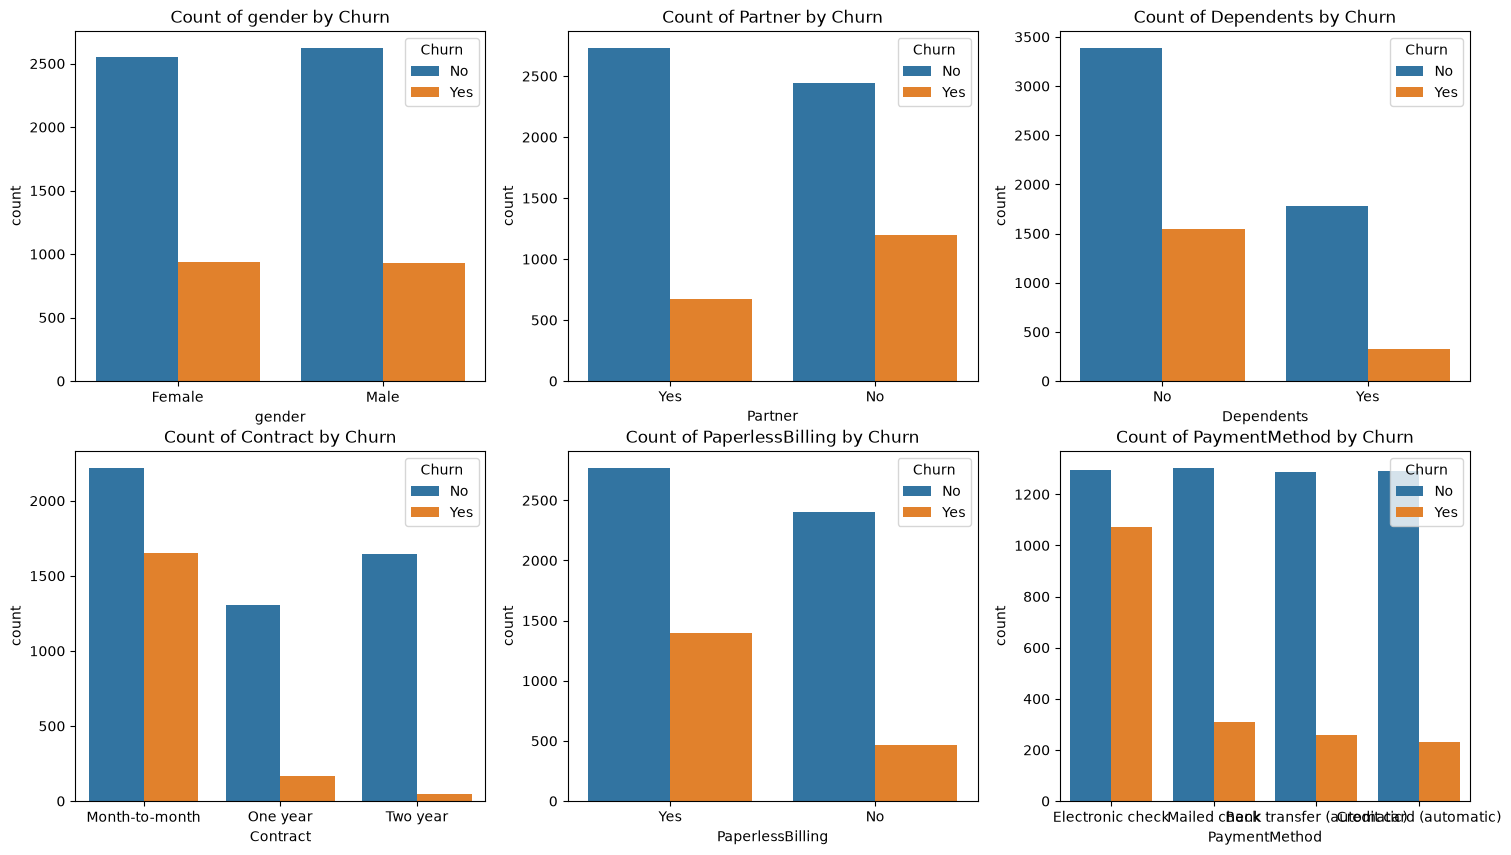

In [32]:
fig, axes = plt.subplots(2, 3, figsize = (18,10))
axes = axes.flatten()

for i, col in enumerate(cols):
    sns.countplot(x=col, hue='Churn', data=df, ax=axes[i])
    axes[i].set_title(f'Count of {col} by Churn')
    axes[i].legend(title='Churn', loc='upper right')

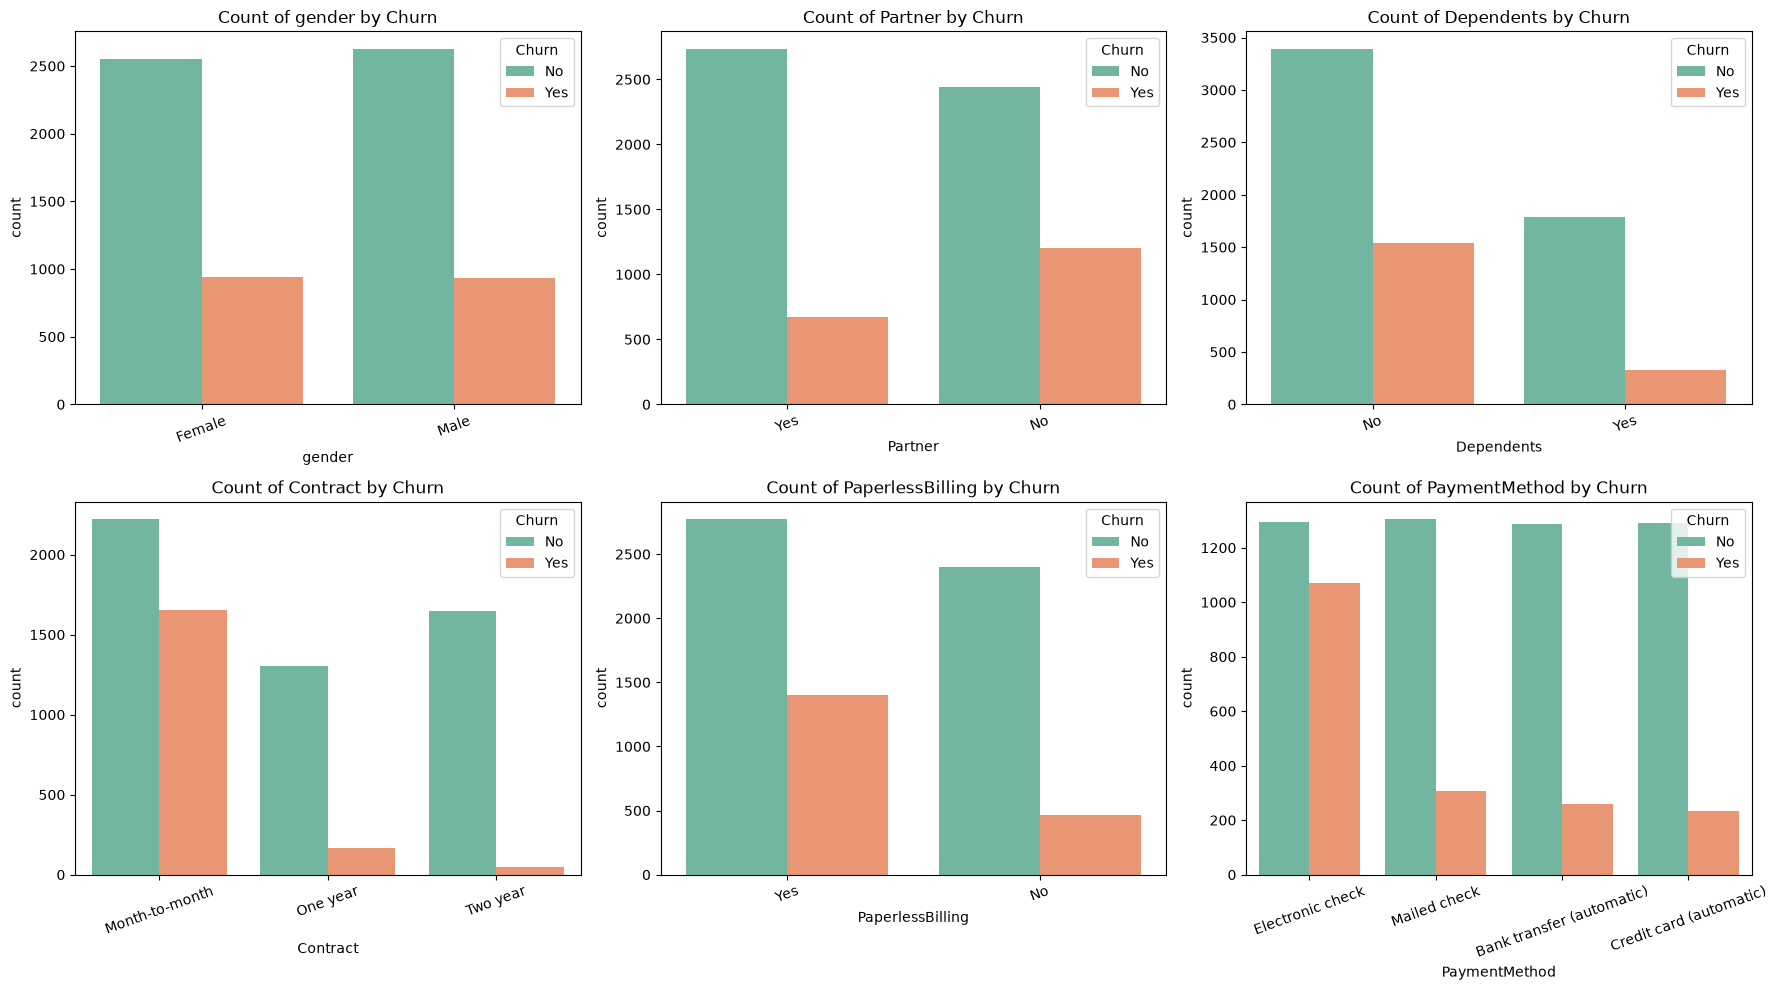

In [33]:
fig, axes = plt.subplots(2,3,figsize=(18,10))
axes = axes.flatten()

for i, col in enumerate(cols):
    sns.countplot(data=df, x = col, hue='Churn', ax = axes[i], palette = 'Set2')
    axes[i].set_title(f'Count of {col} by Churn')
    axes[i].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

C:\Users\Hafizh\AppData\Local\Temp\ipykernel_1212\1046831900.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(x=churn_rate.index, y=churn_rate.values, ax=axes[i], palette='coolwarm')
C:\Users\Hafizh\AppData\Local\Temp\ipykernel_1212\1046831900.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(x=churn_rate.index, y=churn_rate.values, ax=axes[i], palette='coolwarm')
C:\Users\Hafizh\AppData\Local\Temp\ipykernel_1212\1046831900.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(x=churn_rate.index, y=churn_rate.values, 

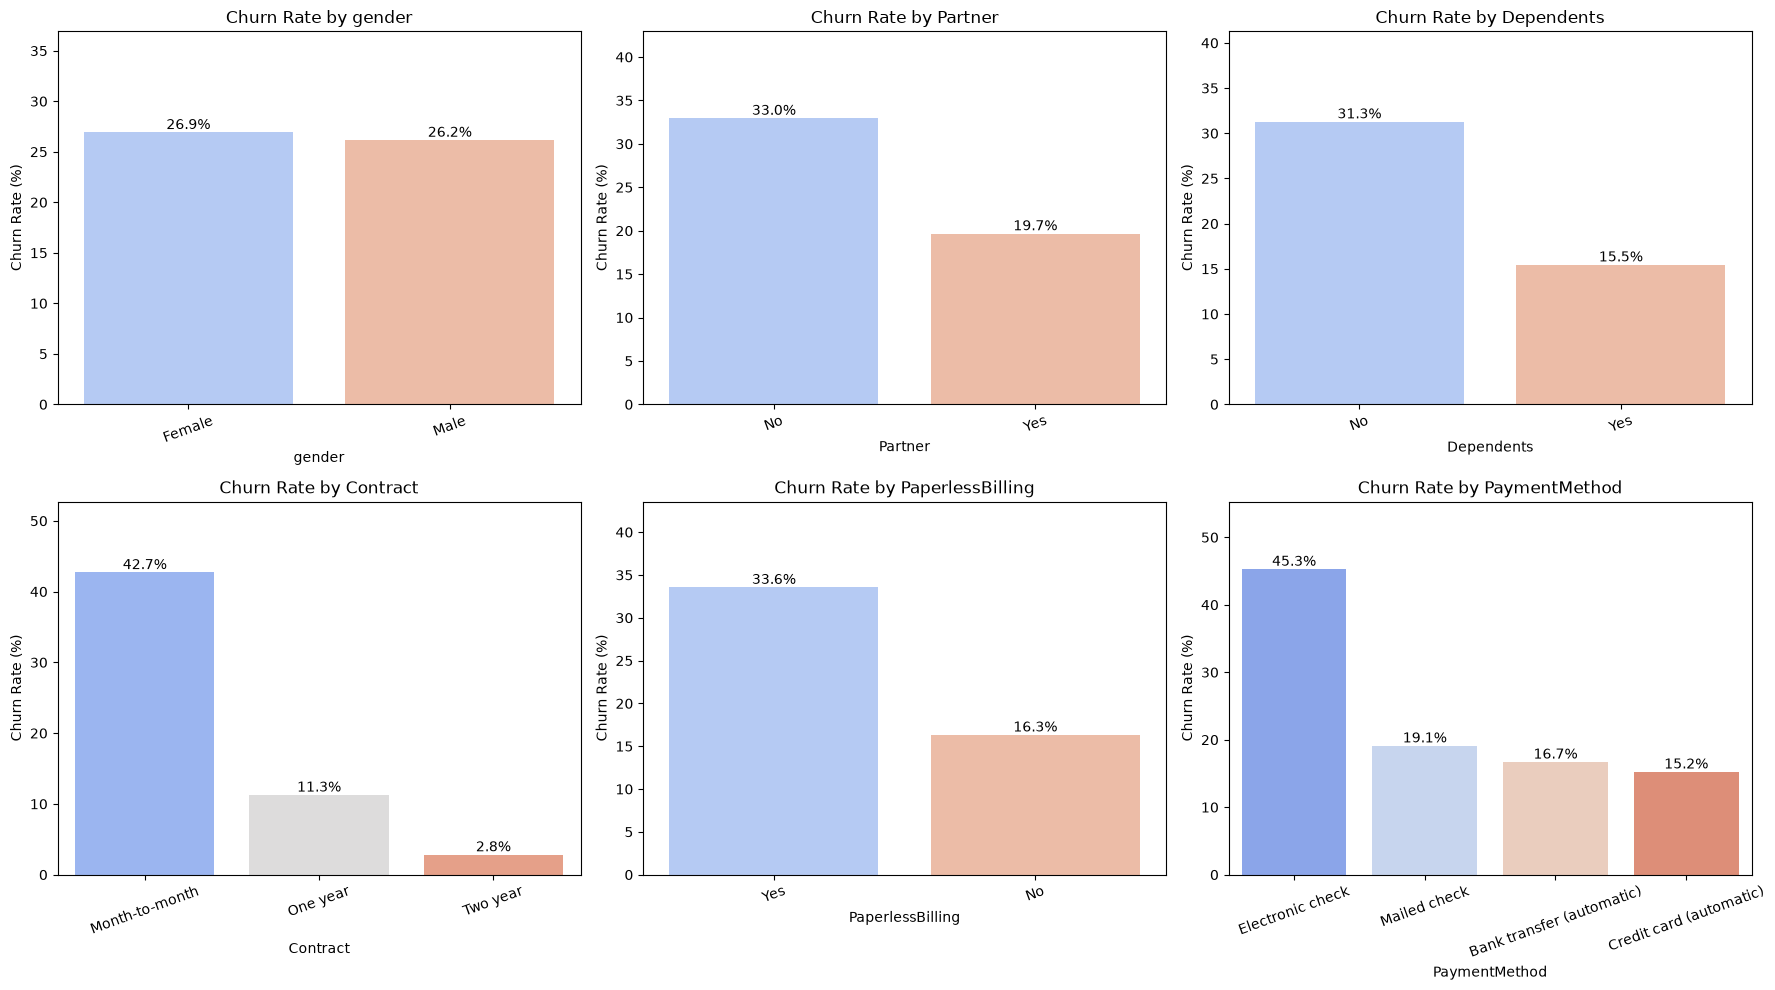

In [34]:
fig, axes = plt.subplots(2, 3, figsize = (18,10))
axes = axes.flatten()
for i, col in enumerate(cols):
    churn_rate = (df.groupby(col)['Churn_num'].mean()*100).sort_values(ascending=False)
    bars = sns.barplot(x=churn_rate.index, y=churn_rate.values, ax=axes[i], palette='coolwarm')
    axes[i].set_title(f'Churn Rate by {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Churn Rate (%)')
    axes[i].set_ylim(0,max (churn_rate.values)+10)
    axes[i].tick_params(axis='x', rotation=20)

    for p in bars.patches:
        axes[i].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., 
                        p.get_height()), ha='center', va='center', fontsize=10, color='black', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

In [35]:
chi2_results = []

for col in cols:
    contingency_table = pd.crosstab(df[col], df['Churn'])
    chi2, p_val, dof, _ = chi2_contingency(contingency_table)
    chi2_results.append({
        'Kolom': col,
        'Chi2': round(chi2, 4),
        'p-value': p_val,
        'Signifikan (p < 0.05)': 'Ya' if p_val < 0.05 else 'Tidak',
        'Cramers V': round(np.sqrt(chi2 / (len(df) * (min(contingency_table.shape) - 1))), 4)
    })

chi2_df = pd.DataFrame(chi2_results).sort_values('p-value')
display(chi2_df)

,Kolom,Chi2,p-value,Signifikan (p < 0.05),Cramers V
3,Contract,1184.5966,5.863038e-258,Ya,0.4101
5,PaymentMethod,648.1423,3.682355e-140,Ya,0.3034
4,PaperlessBilling,258.2776,4.073355e-58,Ya,0.1915
2,Dependents,189.1292,4.924922e-43,Ya,0.1639
1,Partner,158.7334,2.139911e-36,Ya,0.1501
0,gender,0.4841,4.865787e-01,Tidak,0.0083


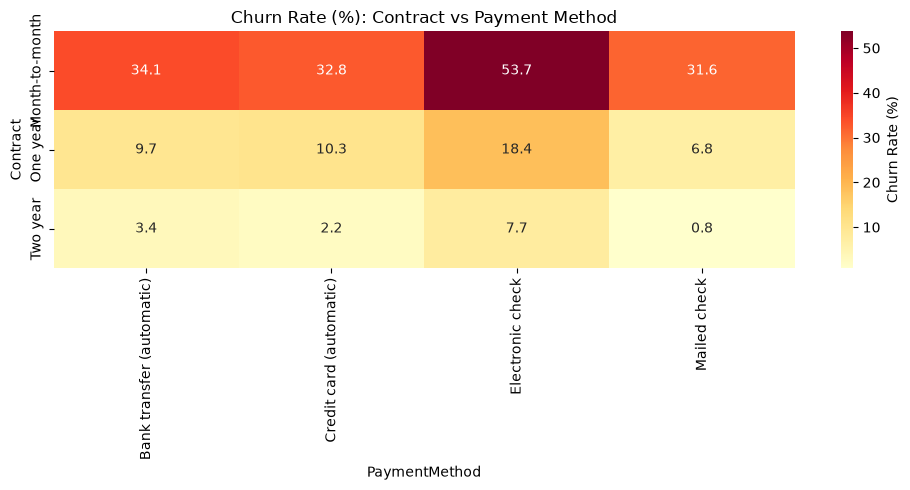

In [36]:
pivot  = df.pivot_table(
    index='Contract', columns='PaymentMethod', values='Churn_num', aggfunc='mean'
)*100

plt.figure(figsize=(10,5))
sns.heatmap(pivot, annot=True, fmt='.1f', cmap='YlOrRd', cbar_kws={'label': 'Churn Rate (%)'})
plt.title('Churn Rate (%): Contract vs Payment Method')
plt.tight_layout()
plt.show()

## Preprocessing 

Data Frame baru untuk preprocessing, hanya mengambil kolom yang relevan untuk analisis. Kolom `Churn` tetap dipertahankan sebagai target.

In [37]:
df_prep = df_raw[cols + ['Churn']].copy()
df_prep.to_csv('bagian2_before_preprocessing.csv', index=False)
print('Saved: bagian2_before_preprocessing.csv | Shape:', df_prep.shape)

### Encoding Kolom Biner (1/0)

In [38]:
# gender
df_prep['gender'] = df_prep['gender'].map({'Female': 1, 'Male': 0})

# Kolom Yes/No
bin_cols = ['Partner', 'Dependents', 'PaperlessBilling', 'Churn']
for col in bin_cols:
    df_prep[col] = df_prep[col].map({'Yes': 1, 'No': 0})

print("Encoding BINER completed")

Encoding BINER completed


### One-Hot Encoding Contract & PaymentMethod

In [39]:
df_prep = pd.get_dummies(df_prep, columns=['Contract'], dtype=int)
df_prep = df_prep.drop(columns=['Contract_Two year'])

df_prep = pd.get_dummies(df_prep, columns=['PaymentMethod'], drop_first=True, dtype=int)

In [40]:
print("Shape:", df_prep.shape)         # Harus tetap (7043, 10)
print("Total NaN:", df_prep.isna().sum().sum())  # Harus 0
print(df_prep.dtypes)                  # int64
df_prep.head()

Shape: (7043, 6)
Total NaN: 0
Churn                                      str
Contract_Month-to-month                  int64
Contract_One year                        int64
PaymentMethod_Credit card (automatic)    int64
PaymentMethod_Electronic check           int64
PaymentMethod_Mailed check               int64
dtype: object


,Churn,Contract_Month-to-month,Contract_One year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,No,1,0,0,1,0
1,No,0,1,0,0,1
2,Yes,1,0,0,0,1
3,No,0,1,0,0,0
4,Yes,1,0,0,1,0
